In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import torch as th
import torch.nn.functional as F

from stable_baselines3 import DQN
from stable_baselines3.common.vec_env import VecNormalize
from stable_baselines3.common.callbacks import BaseCallback

from preprocessing import INDICATORS, preprocess
from environment import AssetVecEnv

In [15]:
df     = preprocess()
config = {
    "price_array": df["close"].values.astype(np.float32),
    "tech_array":  df[INDICATORS].values.astype(np.float32),
    "date":        pd.to_datetime(df["date"]),
}

# ── data splits ──────────────────────────────────────────────────────────────
TRAIN_MONTHS, VAL_MONTHS, TEST_MONTHS = 18, 6, 3

dates = pd.to_datetime(df["date"])
t0        = dates.iloc[0]
train_end = t0        + pd.DateOffset(months=TRAIN_MONTHS)
val_end   = train_end + pd.DateOffset(months=VAL_MONTHS)
test_end  = val_end   + pd.DateOffset(months=TEST_MONTHS)

mask_train = dates <  train_end
mask_val   = (dates >= train_end) & (dates < val_end)
mask_test  = (dates >= val_end)   & (dates < test_end)

def make_config(sub_df):
    return {
        "price_array": sub_df["close"].values.astype(np.float32),
        "tech_array":  sub_df[INDICATORS].values.astype(np.float32),
        "date":        pd.to_datetime(sub_df["date"]),
    }

ENV_KWARGS = dict(initial_cash=10_000.0, commission_rate=1e-3,
                  max_leverage=1.0, allow_shorts=True)

train_env = AssetVecEnv(make_config(df[mask_train].reset_index(drop=True)), n_envs=1, **ENV_KWARGS)
val_env   = AssetVecEnv(make_config(df[mask_val].reset_index(drop=True)),   n_envs=1, **ENV_KWARGS)
test_env  = AssetVecEnv(make_config(df[mask_test].reset_index(drop=True)),  n_envs=1, **ENV_KWARGS)
env = val_env   # downstream cells (activity, rollout) evaluate on val

for name, mask in [("train", mask_train), ("val", mask_val), ("test", mask_test)]:
    d = dates[mask]
    print(f"{name:5s}  bars={mask.sum():6d}  {d.iloc[0].date()} → {d.iloc[-1].date()}")

norm_train_env = VecNormalize(train_env, norm_reward=False)
norm_val_env   = VecNormalize(val_env,   norm_reward=False, training=False)
norm_test_env  = VecNormalize(test_env,  norm_reward=False, training=False)

Data shape: (65989, 7)
Date range: 2017-12-31 23:00:00 -> 2025-07-17 13:00:00
Processed shape: (65989, 93)
Indicators (86): ['volume_adi', 'volume_obv', 'volume_cmf', 'volume_fi', 'volume_em', 'volume_sma_em', 'volume_vpt', 'volume_vwap', 'volume_mfi', 'volume_nvi', 'volatility_bbm', 'volatility_bbh', 'volatility_bbl', 'volatility_bbw', 'volatility_bbp', 'volatility_bbhi', 'volatility_bbli', 'volatility_kcc', 'volatility_kch', 'volatility_kcl', 'volatility_kcw', 'volatility_kcp', 'volatility_kchi', 'volatility_kcli', 'volatility_dcl', 'volatility_dch', 'volatility_dcm', 'volatility_dcw', 'volatility_dcp', 'volatility_atr', 'volatility_ui', 'trend_macd', 'trend_macd_signal', 'trend_macd_diff', 'trend_sma_fast', 'trend_sma_slow', 'trend_ema_fast', 'trend_ema_slow', 'trend_vortex_ind_pos', 'trend_vortex_ind_neg', 'trend_vortex_ind_diff', 'trend_trix', 'trend_mass_index', 'trend_dpo', 'trend_kst', 'trend_kst_sig', 'trend_kst_diff', 'trend_ichimoku_conv', 'trend_ichimoku_base', 'trend_ichim

In [ ]:
from rainbow_dqn import DuelingQNetwork, DuelingDQNPolicy, RainbowDQN, StickyDQN

print("DuelingQNetwork, DuelingDQNPolicy, RainbowDQN, StickyDQN — imported.")

In [18]:
model = StickyDQN(
    policy                 = DuelingDQNPolicy,
    env                    = norm_train_env,
    mean_hold              = 50,
    switching_cost         = 0.5,
    replay_buffer_class  = PrioritizedReplayBuffer,

    
    n_steps                = 10,
    learning_rate          = 1e-4,
    buffer_size            = 100_000,
    learning_starts        = 2_000,
    batch_size             = 64,
    tau                    = 1.0,
    gamma                  = 0.999,
    train_freq             = 4,
    gradient_steps         = 1,
    target_update_interval = 1_000,
    exploration_fraction   = 0.50,
    exploration_initial_eps= 1.0,
    exploration_final_eps  = 0.05,
    policy_kwargs          = dict(net_arch=[64, 64]),
    verbose                = 0,
    seed                   = 16,
)

Output()

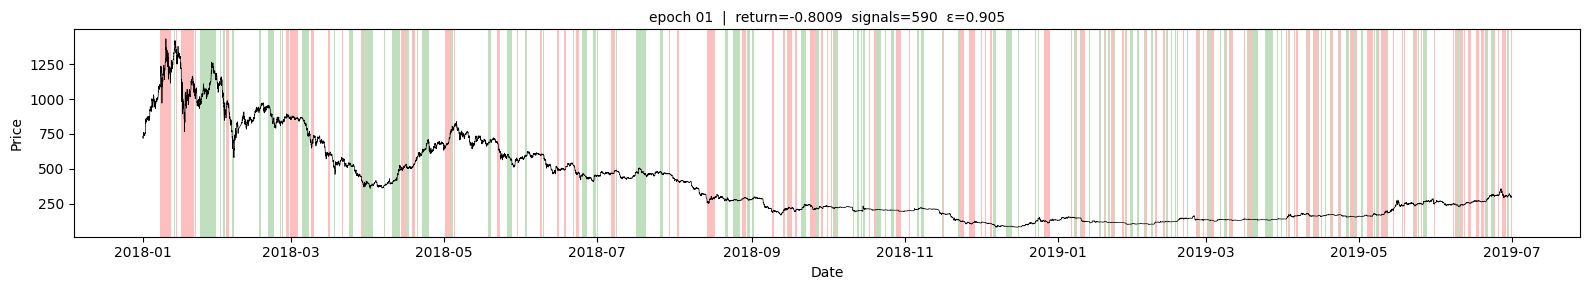

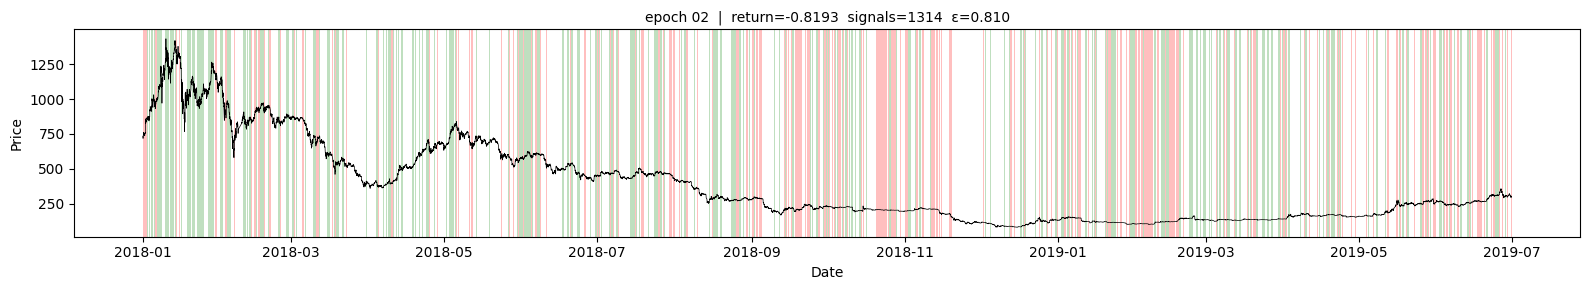

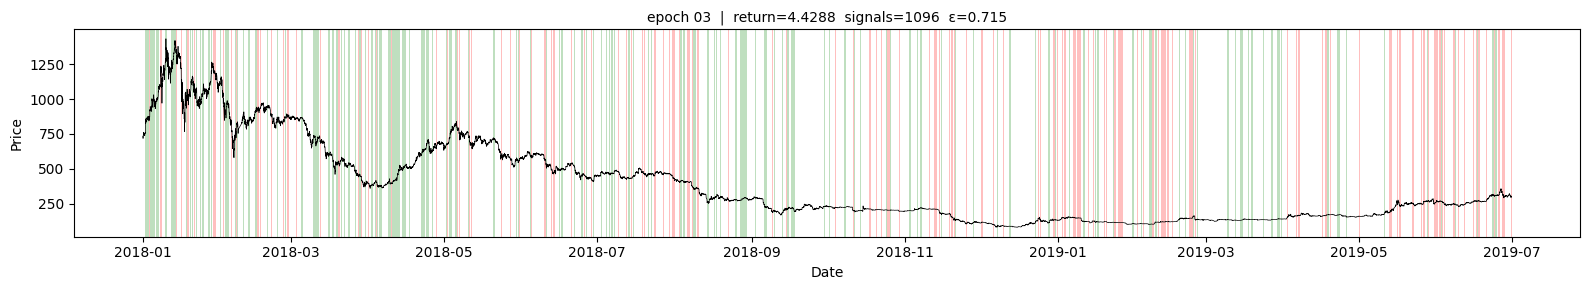

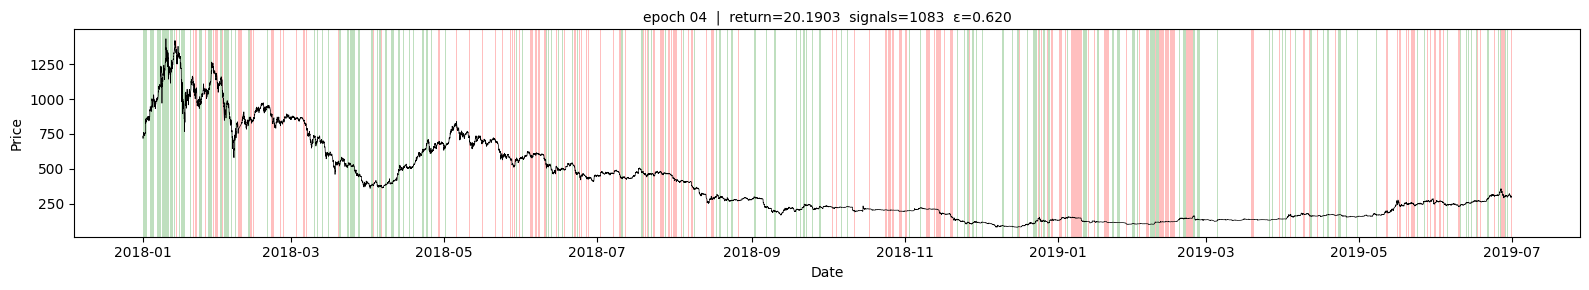

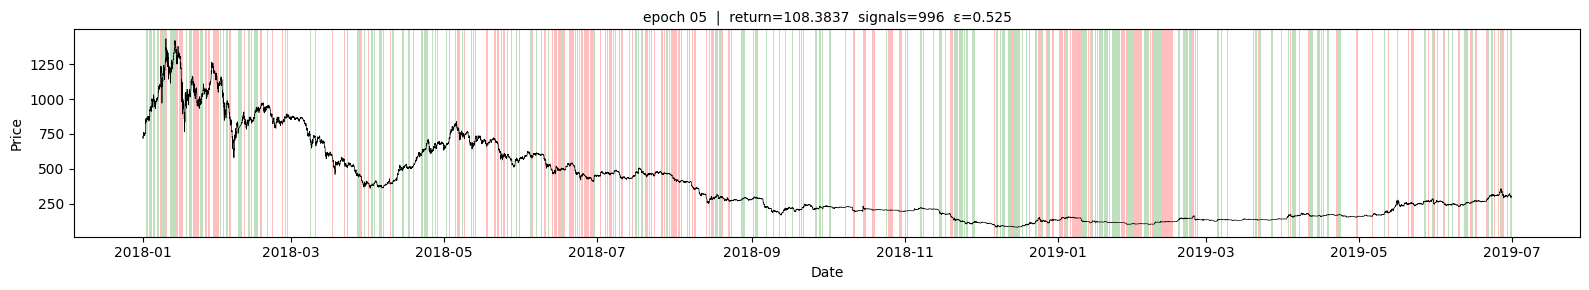

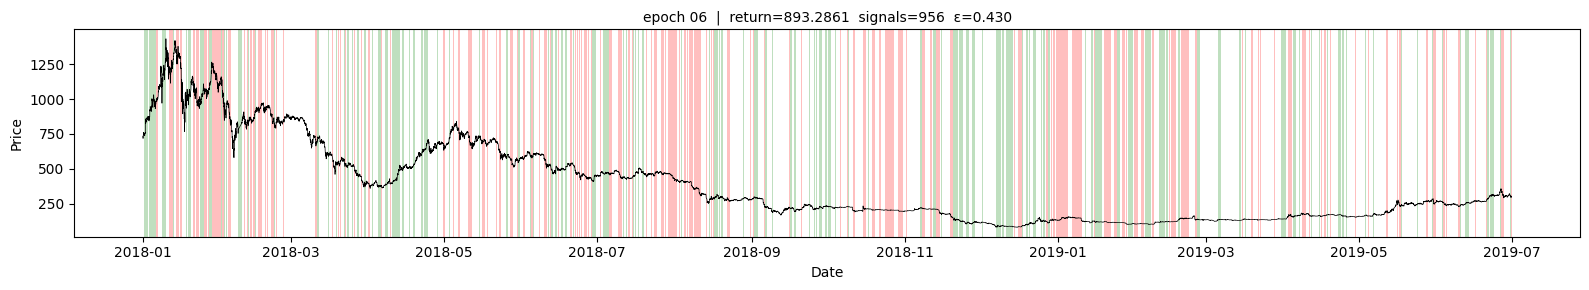

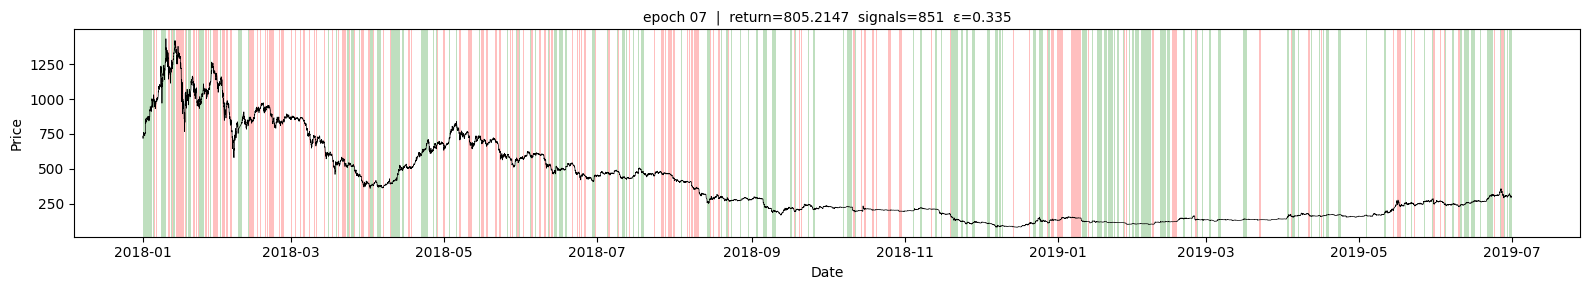

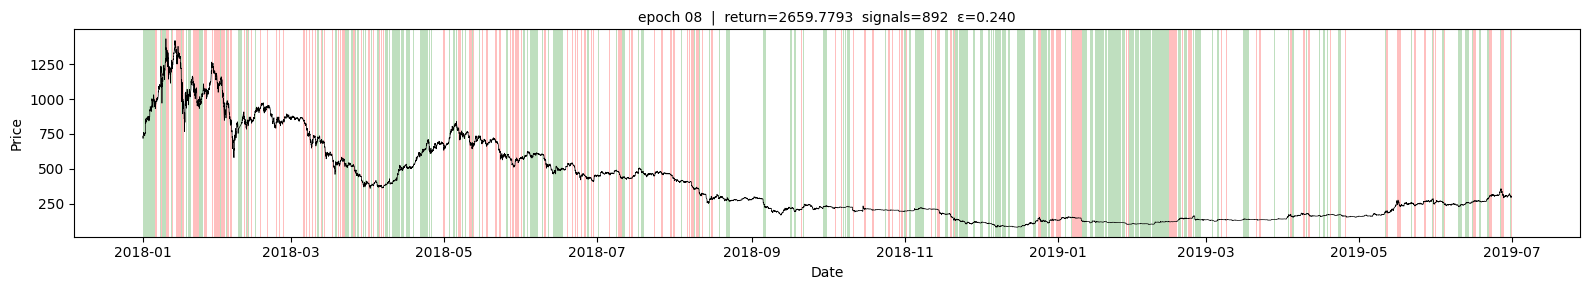

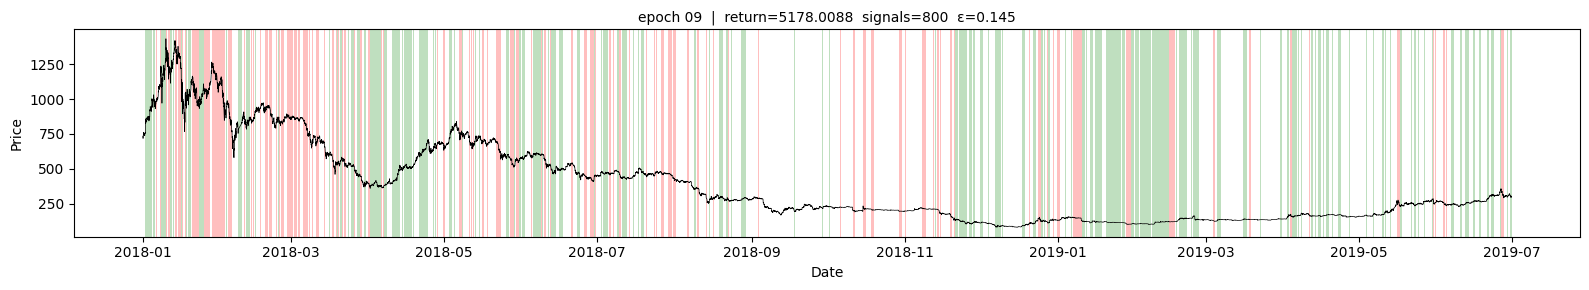

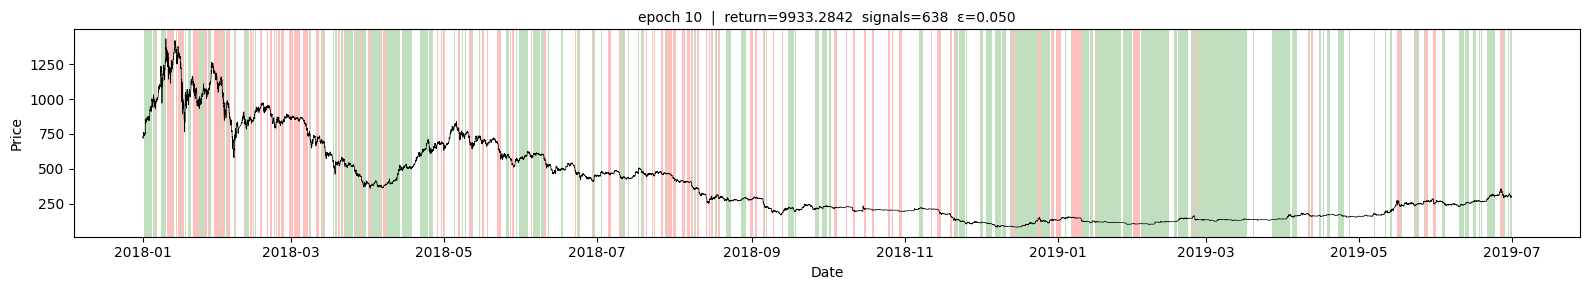

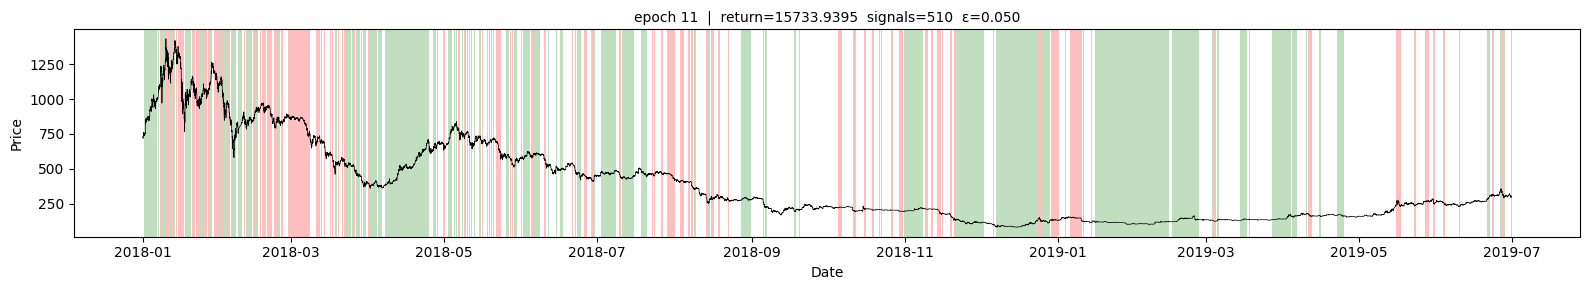

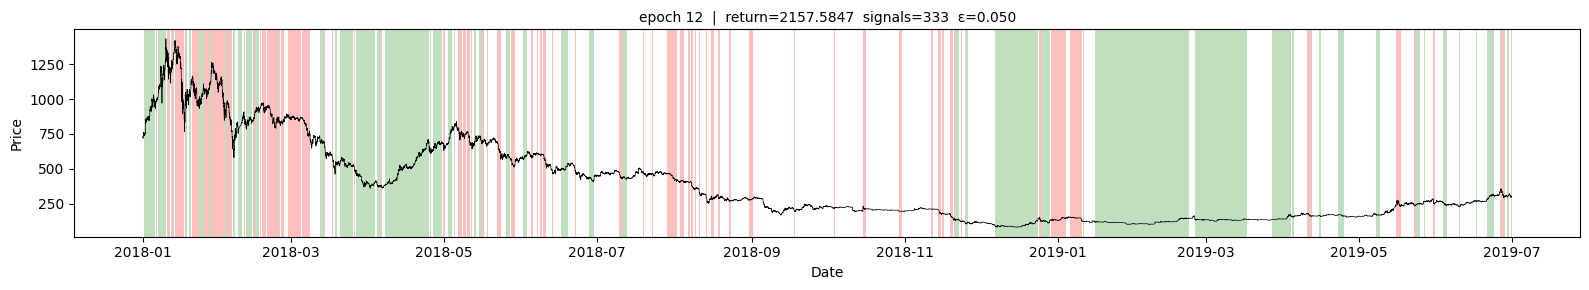

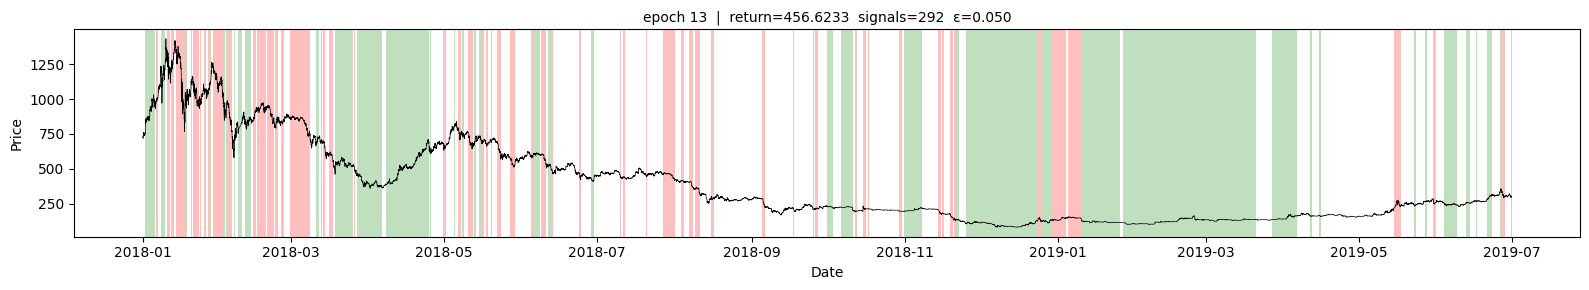

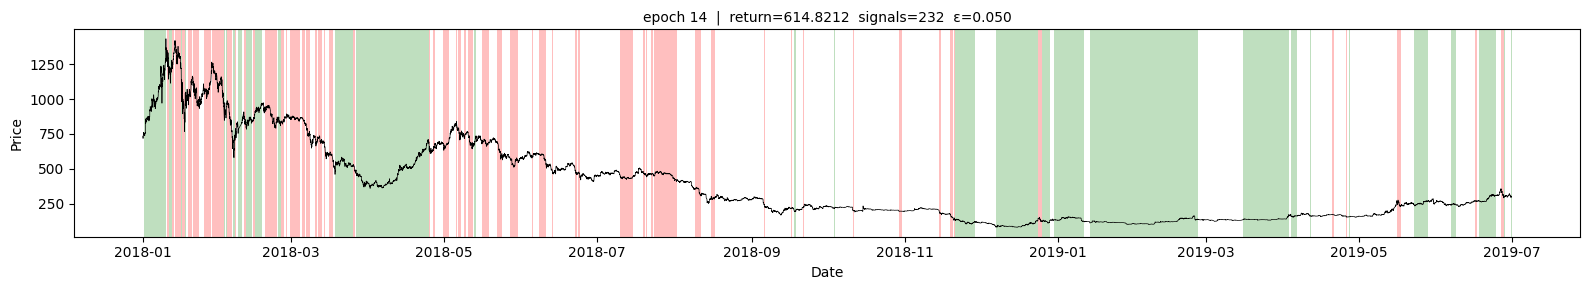

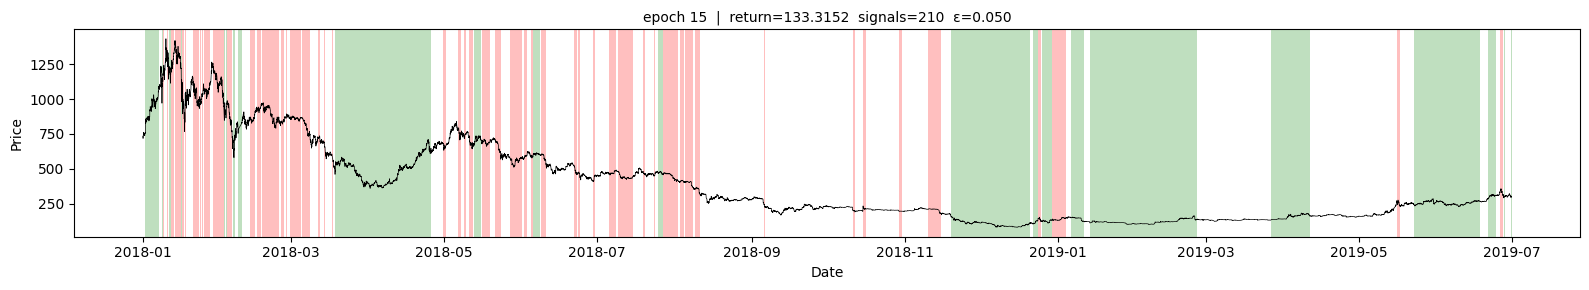

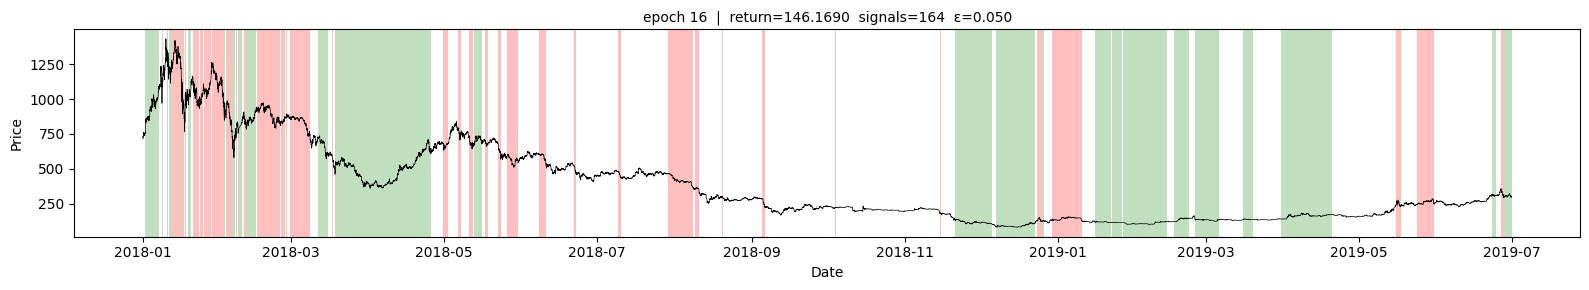

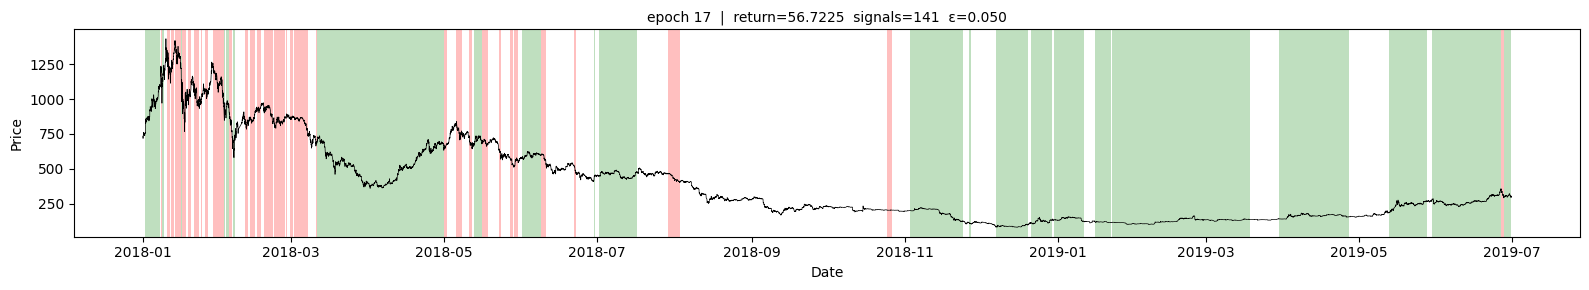

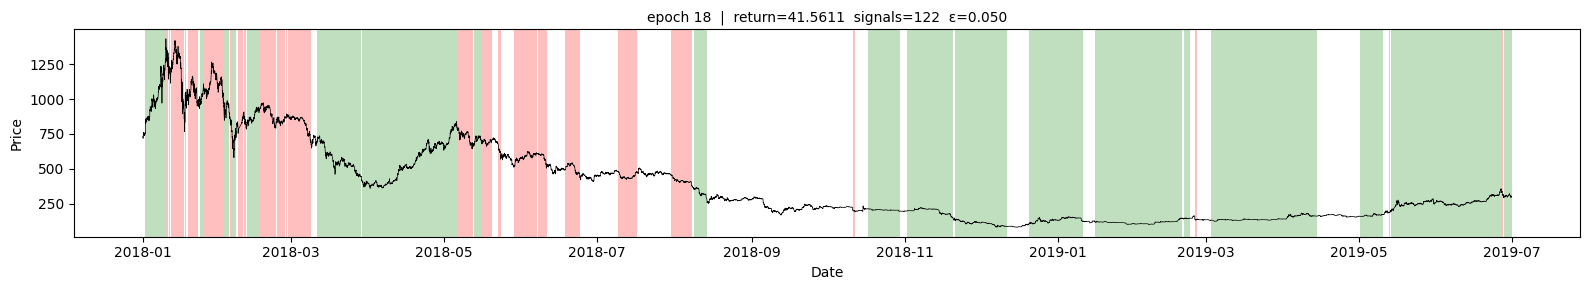

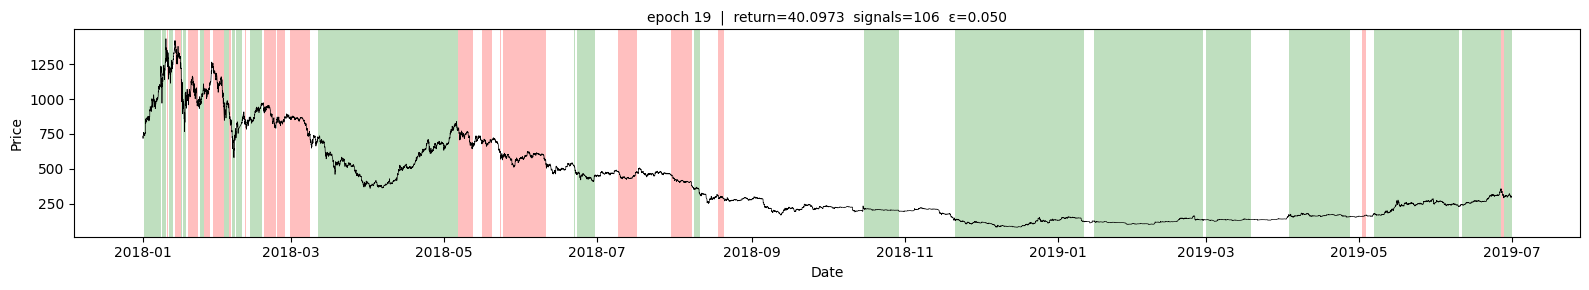

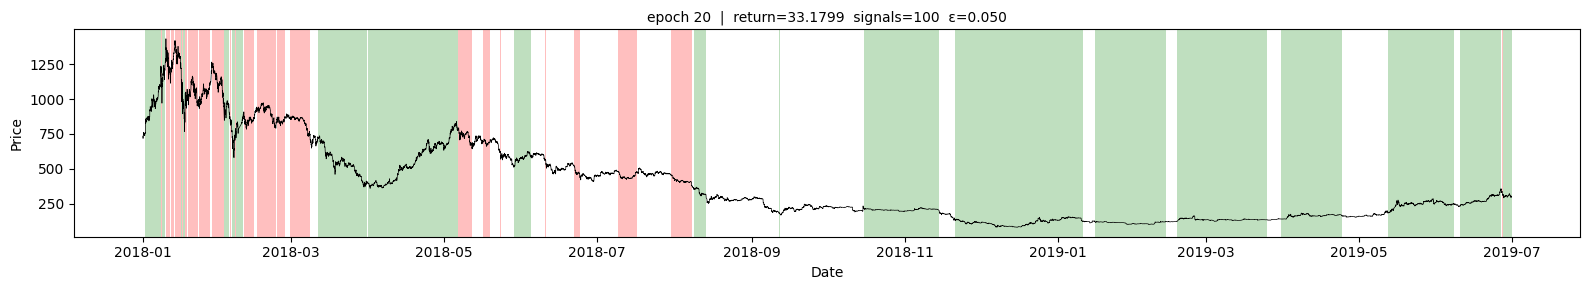

In [19]:
class PlotCallback(BaseCallback):
    """Plots position chart after every episode."""

    def __init__(self, env: AssetVecEnv):
        super().__init__()
        self.env    = env
        self.dates  = pd.to_datetime(env.ts_ary, unit="ns")
        self.prices = env.price_ary
        self.epoch  = 0

    def _on_step(self) -> bool:
        for info in self.locals["infos"]:
            if "episode" not in info:
                continue
            self.epoch += 1
            ep  = info["episode"]
            eps = self.model.exploration_rate
            self._plot(ep, self.epoch, eps)
        return True

    def _plot(self, ep: dict, epoch: int, eps: float) -> None:
        activity   = ep["activity"]
        pos_sparse = activity["position_size"].groupby(level=0).last()
        pos_dense  = (pos_sparse
                      .reindex(self.dates.union(pos_sparse.index))
                      .ffill()
                      .reindex(self.dates)
                      .fillna(0.0))
        direction  = np.sign(pos_dense)

        fig, ax = plt.subplots(figsize=(16, 3))
        ax.plot(self.dates, self.prices, color="black", linewidth=0.5)

        def shade(mask, color):
            i0 = None
            for i, v in enumerate(mask):
                if v and i0 is None:  i0 = i
                elif not v and i0 is not None:
                    ax.axvspan(self.dates[i0], self.dates[i],
                               color=color, alpha=0.25, linewidth=0)
                    i0 = None
            if i0 is not None:
                ax.axvspan(self.dates[i0], self.dates[-1],
                           color=color, alpha=0.25, linewidth=0)

        shade(direction.values ==  1, "green")
        shade(direction.values == -1, "red")

        ax.set_title(f"epoch {epoch:02d}  |  return={ep['r']:.4f}  "
                     f"signals={ep['l']}  ε={eps:.3f}", fontsize=10)
        ax.set_xlabel("Date"); ax.set_ylabel("Price")
        plt.tight_layout(); plt.show()


N_EPOCHS    = 20
total_steps = N_EPOCHS * train_env.T

model.learn(
    total_timesteps     = total_steps,
    callback            = PlotCallback(train_env),
    reset_num_timesteps = True,
    progress_bar        = True,
)

In [ ]:
# Usage:
#
# Standard (NStepReplayBuffer):
#   model = StickyDQN('MlpPolicy', env, n_steps=3, mean_hold=50, switching_cost=0.1)
#
# With PER (PrioritizedReplayBuffer):
#   model = StickyDQN('MlpPolicy', env, n_steps=3, mean_hold=50, switching_cost=0.1,
#                     replay_buffer_class=PrioritizedReplayBuffer,
#                     per_alpha=0.6, per_beta=0.4, per_epsilon=1e-6)

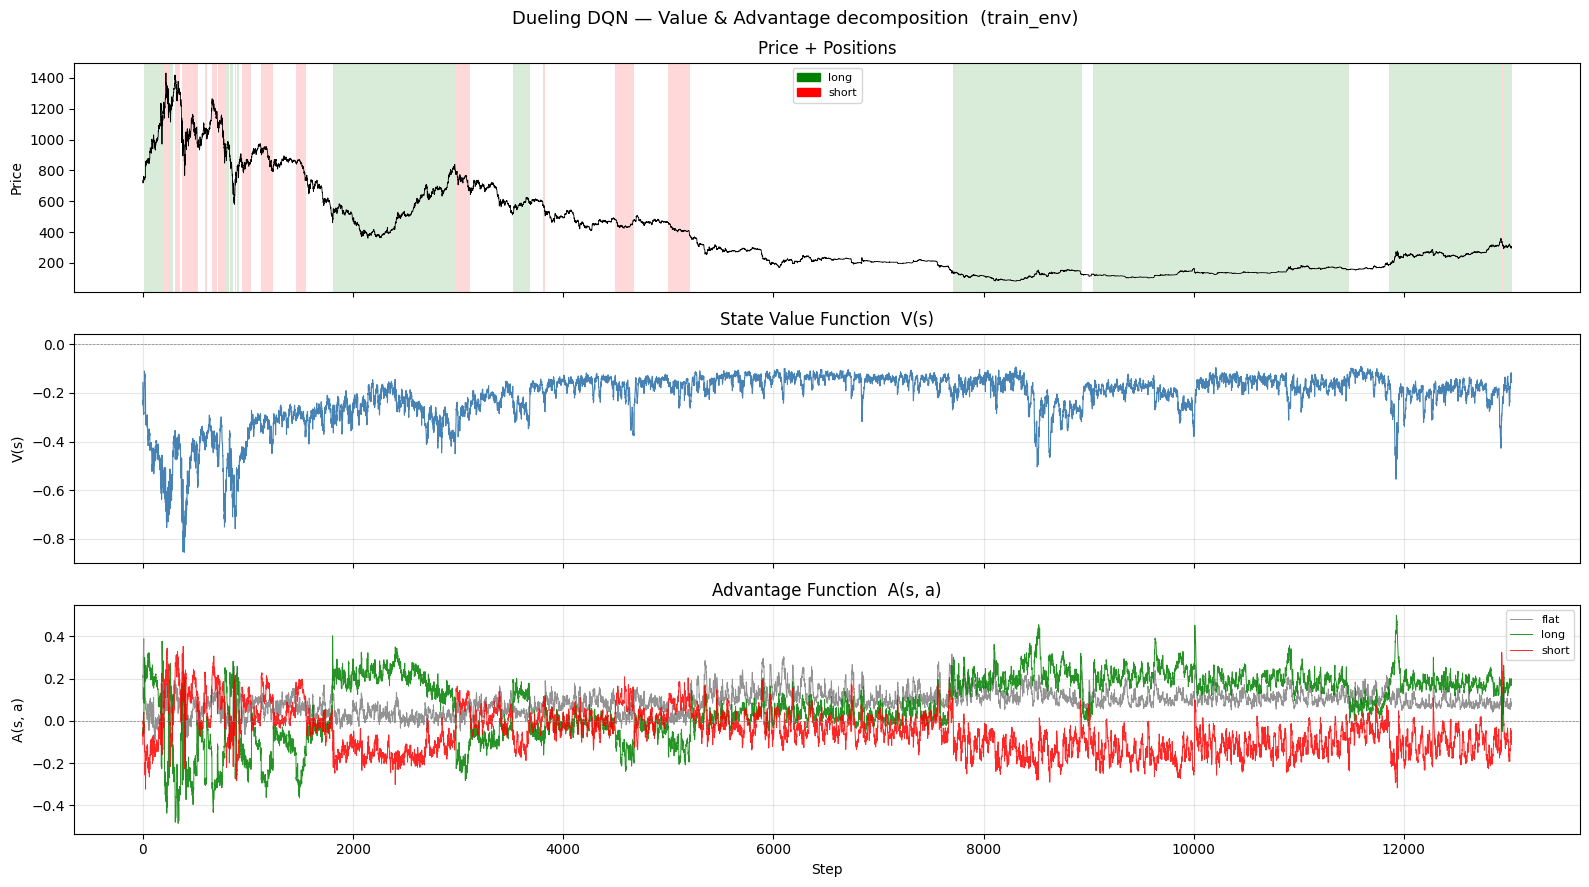

In [20]:
assert hasattr(model.q_net, "value_head"), "Model must use DuelingQNetwork (DuelingDQNPolicy)"

ACTION_LABELS = ["flat", "long", "short"]
ACTION_COLORS = ["gray", "green", "red"]


def dueling_decompose(model, obs_arr: np.ndarray):
    """Return V(s) (T,) and A(s,a) (T, n_actions) for a batch of observations."""
    q_net = model.q_net
    obs_t = th.tensor(obs_arr, dtype=th.float32, device=model.device)
    with th.no_grad():
        latent = q_net.q_net(q_net.extract_features(obs_t, q_net.features_extractor))
        V = q_net.value_head(latent).cpu().numpy().flatten()   # (T,)
        A = q_net.adv_head(latent).cpu().numpy()               # (T, n_actions)
    return V, A


# ── roll out one full episode on train_env ────────────────────────────────────
norm_train_env.training = False   # freeze normalisation stats during rollout
obs = norm_train_env.reset()
all_obs, all_actions = [], []
done = False
while not done:
    all_obs.append(obs[0].copy())
    action, _ = model.predict(obs, deterministic=True)
    obs, _, dones, _ = norm_train_env.step(action)
    all_actions.append(int(action[0]))
    done = bool(dones[0])
norm_train_env.training = True    # restore

obs_arr = np.array(all_obs)          # (T, obs_dim)
V, A    = dueling_decompose(model, obs_arr)
T       = len(V)
prices  = train_env.price_ary[:T]

# ── plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(16, 9), sharex=True)

# price + position shading
ax = axes[0]
ax.plot(prices, color="black", linewidth=0.6)
for t in range(T - 1):
    a = all_actions[t]
    if a != 0:
        ax.axvspan(t, t + 1, color=ACTION_COLORS[a], alpha=0.15, linewidth=0)
ax.set_ylabel("Price")
ax.set_title("Price + Positions")
ax.legend(
    handles=[mpatches.Patch(color=c, label=l)
             for c, l in zip(ACTION_COLORS[1:], ACTION_LABELS[1:])],
    fontsize=8,
)

# value function
ax = axes[1]
ax.plot(V, color="steelblue", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.5, linestyle="--")
ax.set_ylabel("V(s)")
ax.set_title("State Value Function  V(s)")
ax.grid(alpha=0.3)

# advantage function
ax = axes[2]
for i, (label, color) in enumerate(zip(ACTION_LABELS, ACTION_COLORS)):
    ax.plot(A[:, i], color=color, linewidth=0.7, alpha=0.85, label=label)
ax.axhline(0, color="gray", linewidth=0.5, linestyle="--")
ax.set_ylabel("A(s, a)")
ax.set_title("Advantage Function  A(s, a)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
ax.set_xlabel("Step")

fig.suptitle("Dueling DQN — Value & Advantage decomposition  (train_env)", fontsize=13)
plt.tight_layout()
plt.show()
